# Practical Assignment 3: Feedforward Neural Network on CIFAR-10 Dataset

**Aim:** Implement Feedforward neural networks with Keras and TensorFlow on the CIFAR-10 natural image dataset (10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

**Key Concepts to Remember:**
1. **Input:** 32x32x3 color images flattened to 3072 features, normalized by dividing by `255.0`.
2. **Architecture:** Dense(512) $\to$ BatchNormalization $\to$ Dropout $\to$ Dense(256) $\to$ Dense(10, softmax).
3. **Regularization:** Batch Normalization stabilizes training on natural images.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Step 1: Load CIFAR-10 Data
df = pd.read_csv(r'd:/workspace01/4th year/DL/LabPracticesIV_DEEP_LEARNING/dataset/cifar10/train.csv', nrows=6000)
X = df.iloc[:, :-1].values.astype('float32') / 255.0  # 3072 pixel values
y = df.iloc[:, -1].values.astype('int32')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training shape: {X_train.shape}, Test shape: {X_test.shape}')

# Step 2: Build Feedforward Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.summary()

# Step 3: Compile and Train Model
model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.15, verbose=1)

# Step 4: Evaluate and Predict
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f'\nCIFAR-10 Test Accuracy: {acc*100:.2f}% | Test Loss: {loss:.4f}')

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
sample_pred = class_names[np.argmax(model.predict(X_test[:1], verbose=0))]
sample_true = class_names[y_test[0]]
print(f'Sample Test Prediction: {sample_pred} | Actual: {sample_true}')


Training shape: (4800, 3072), Test shape: (1200, 3072)
Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│

### Step 5: Plot Training & Validation Loss and Accuracy Curves

Visualizing loss and accuracy trajectories across training epochs confirms convergence and checks for overfitting.


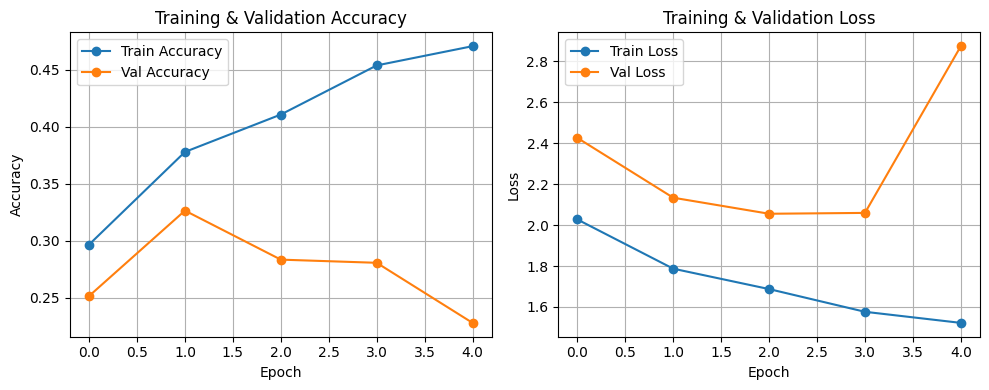

In [2]:
import matplotlib.pyplot as plt

# Step 5: Plot Training & Validation Accuracy and Loss Curves
plt.figure(figsize=(10, 4))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
